# HOPV data understanding and preparation

Parses the Harvard Organic Photovoltaics 2015 (HOPV-15) dataset, explores the HOMO/LUMO targets and device metadata, and computes the RDKit descriptor table that the models use. Runs on the public dataset (`python scripts/download_hopv.py`); if the course copy of HOPV is present in `data/course/`, that copy is used instead.

The raw file is not a table: every molecule is a block of lines with its SMILES string, its InChI identifier, a comma-separated line of experimental values and then the conformer geometries. `src/data.py::parse_hopv` uses the InChI line as the block marker and takes the line before it (SMILES) and the line after it (experimental values).

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from rdkit.Chem import Draw, MolFromSmiles

from src.data import PROCESSED_DIR, hopv_path, load_hopv, load_hopv_table
from src.features import descriptor_frame

df = load_hopv()
print(f"Parsed {len(df)} molecules from {hopv_path().name}")
df.head()

Parsed 350 molecules from HOPV_15_revised_2.data


,smiles,doi,InChIKEY,construction,architecture,complement,homo,lumo,electrochemical_gap,optical_gap,pce,voc,jsc,ff
0,Cc1ccc(-c2c3cc(-c4ccc(-c5sc(-c6cccs6)c6cc(S(C)...,10.1021/ar5000743,BOUZSMSNJFUUCG-UHFFFAOYSA-N,polymer,bulk,PC71BM,-5.04,-3.57,1.47,1.59,7.81,0.69,17.07,66.3
1,CN1c2ccccc2C(=C2c3ccc(-c4cccs4)cc3N(C)C2=O)C1=O,10.1039/C3PY01598J,PAPOKCOIPOLVSC-BNEIJSFPSA-N,polymer,bulk,PC71BM,NaN,NaN,NaN,NaN,3.00,0.89,5.40,63.0
2,Cc1cc(-c2cc3c4nsnc4c(-c4cc(C)c(-c5cccs5)s4)cc3...,10.1021/ja210687r,IKPPCQWOLGDYAQ-UHFFFAOYSA-N,polymer,bulk,PC61BM,-5.16,-3.77,1.39,1.54,6.30,0.76,12.00,69.0
3,Cn1c2ccccc2c2ccc(-c3ccc(-c4ccc(C5=C(c6ccccc6)C...,10.1021/ar900061z,LZAUYQACJPMHMN-UHFFFAOYSA-N,polymer,bulk,PC61BM,NaN,NaN,NaN,2.00,1.51,0.75,4.68,44.5
4,Cc1cc(-c2c3cc(-c4cccs4)sc3c(-c3cc(C)c(C)s3)c3c...,10.1039/C3PY01598J,RJIQMHRLDYGXFS-HYXXFLLTSA-N,polymer,bulk,PC71BM,-5.64,-3.98,1.66,NaN,5.70,0.90,10.16,62.0


## 1. Missing values and duplicates

The file writes missing values as the string `"nan"`; the parser converts them to real NaNs.

In [2]:
both_present = df[['homo', 'lumo']].notna().all(axis=1).sum()
homo_only = (df['homo'].notna() & df['lumo'].isna()).sum()
lumo_only = (df['homo'].isna() & df['lumo'].notna()).sum()
both_missing = df[['homo', 'lumo']].isna().all(axis=1).sum()
print(f"HOMO and LUMO present: {both_present}")
print(f"Only HOMO present:     {homo_only}")
print(f"Only LUMO present:     {lumo_only}")
print(f"Both missing:          {both_missing}")
print(f"Duplicate SMILES:      {df['smiles'].duplicated().sum()}")

HOMO and LUMO present: 233
Only HOMO present:     12
Only LUMO present:     0
Both missing:          105
Duplicate SMILES:      3


## 2. Device metadata

In [3]:
for col in ['construction', 'architecture', 'complement']:
    print(df[col].value_counts(), "\n")

construction
polymer     220
molecule    127
Name: count, dtype: int64 

architecture
bulk       270
DSSC        64
bilayer     13
Name: count, dtype: int64 

complement
PC61BM    139
PC71BM    133
TiO2       64
C60         9
ICBA        1
PDI         1
Name: count, dtype: int64 



In [4]:
df.describe().round(3)

,homo,lumo,electrochemical_gap,optical_gap,pce,voc,jsc,ff
count,245.000,233.000,233.000,213.000,343.000,341.000,340.000,339.00
mean,-5.268,-3.368,1.905,1.747,3.832,0.741,8.736,54.36
std,0.229,0.311,0.335,0.265,2.341,0.148,4.478,13.17
min,-6.300,-4.150,1.100,1.100,0.000,0.154,0.036,22.00
25%,-5.400,-3.600,1.700,1.600,1.770,0.650,5.160,44.00
50%,-5.240,-3.410,1.840,1.730,3.940,0.750,9.170,57.00
75%,-5.120,-3.190,2.080,1.900,5.700,0.850,11.918,64.00
max,-4.700,-2.480,3.320,2.780,10.200,1.510,18.200,77.00


## 3. HOMO and LUMO distributions

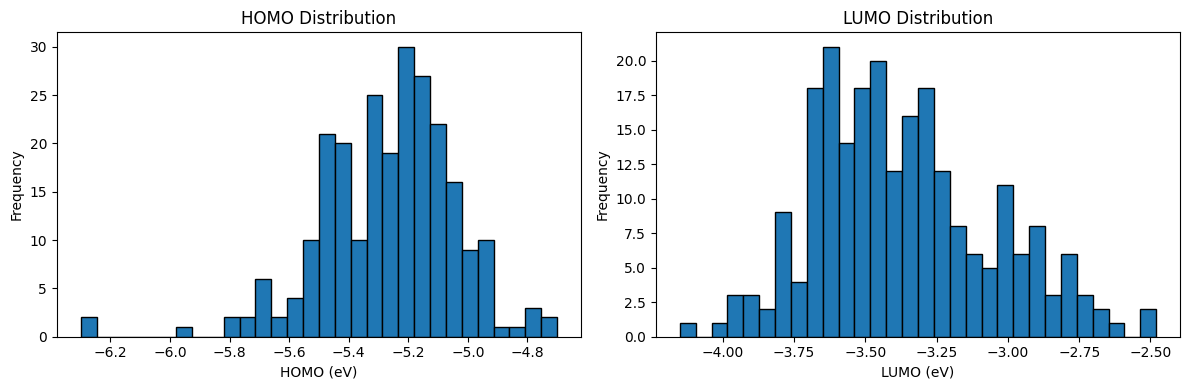

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['homo', 'lumo']):
    ax.hist(df[col].dropna(), bins=30, edgecolor='black')
    ax.set_xlabel(f'{col.upper()} (eV)')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{col.upper()} Distribution')
plt.tight_layout()
plt.show()

In [6]:
numerical_columns = ['homo', 'lumo', 'electrochemical_gap', 'optical_gap', 'pce', 'voc', 'jsc', 'ff']
df[numerical_columns].corr().round(2)

,homo,lumo,electrochemical_gap,optical_gap,pce,voc,jsc,ff
homo,1.00,0.26,-0.45,-0.33,0.10,-0.37,0.25,0.14
lumo,0.26,1.00,0.74,0.56,-0.07,-0.04,-0.03,-0.05
electrochemical_gap,-0.45,0.74,1.00,0.75,-0.14,0.22,-0.21,-0.15
optical_gap,-0.33,0.56,0.75,1.00,-0.30,0.21,-0.45,-0.26
pce,0.10,-0.07,-0.14,-0.30,1.00,0.28,0.90,0.81
voc,-0.37,-0.04,0.22,0.21,0.28,1.00,0.03,0.14
jsc,0.25,-0.03,-0.21,-0.45,0.90,0.03,1.00,0.67
ff,0.14,-0.05,-0.15,-0.26,0.81,0.14,0.67,1.00


## 4. Example molecule

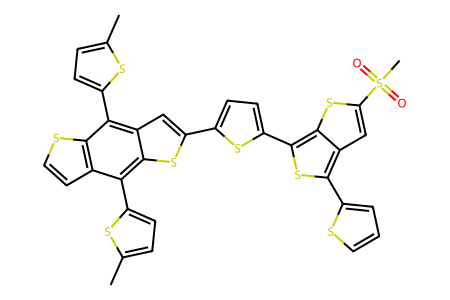

In [7]:
Draw.MolToImage(MolFromSmiles(df.loc[0, 'smiles']), size=(450, 300))

## 5. Model input table

One row per unique SMILES: the SMILES string, all RDKit descriptors, then the targets (`homo`, `lumo`, and `stability` when the course labels are available). Saved to `data/processed/xy_df_hopv.csv`.

In [8]:
targets = load_hopv_table()
descriptors = descriptor_frame(targets['smiles'])
xy_df = pd.concat([targets[['smiles']], descriptors, targets.drop(columns='smiles')], axis=1)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
xy_df.to_csv(PROCESSED_DIR / 'xy_df_hopv.csv', index=False)
print(f"{xy_df.shape[0]} molecules x {descriptors.shape[1]} descriptors -> data/processed/xy_df_hopv.csv")

347 molecules x 217 descriptors -> data/processed/xy_df_hopv.csv
